<a href="https://colab.research.google.com/github/jostina/Netflix-Dataset/blob/main/Task_4_%E2%80%93_Netflix_Trend_Prediction_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Import libraries

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

In [2]:
# Load the clean dataset
df = pd.read_csv("/content/netflix_titles_cleaned.csv")

# Display the first five rows
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,date_added_year,date_added_month,date_added_month_name,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,9,September,90,min
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,9,September,1,Season
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,9,September,1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,9,September,91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,9,September,125,min


2. Load the clean Netflix dataset

In [3]:
# Dataset information
df.info()

# Check missing values
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   show_id                8790 non-null   object
 1   type                   8790 non-null   object
 2   title                  8790 non-null   object
 3   director               8790 non-null   object
 4   country                8790 non-null   object
 5   date_added             8790 non-null   object
 6   release_year           8790 non-null   int64 
 7   rating                 8790 non-null   object
 8   duration               8790 non-null   object
 9   listed_in              8790 non-null   object
 10  date_added_year        8790 non-null   int64 
 11  date_added_month       8790 non-null   int64 
 12  date_added_month_name  8790 non-null   object
 13  duration_value         8790 non-null   int64 
 14  duration_unit          8790 non-null   object
dtypes: int64(4), object(1

,0
show_id,0
type,0
title,0
director,0
country,0
date_added,0
release_year,0
rating,0
duration,0
listed_in,0


3. Prepare release-year data

In [4]:
# Check release years
df["release_year"].describe()

,release_year
count,8790.000000
mean,2014.183163
std,8.825466
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [5]:
# Remove missing release years
trend_df = df.dropna(subset=["release_year"]).copy()

# Convert release_year to integer
trend_df["release_year"] = trend_df["release_year"].astype(int)

# Display the first five rows
trend_df[["title", "type", "release_year"]].head()

,title,type,release_year
0,Dick Johnson Is Dead,Movie,2020
1,Ganglands,Tv Show,2021
2,Midnight Mass,Tv Show,2021
3,Confessions of an Invisible Girl,Movie,2021
4,Sankofa,Movie,1993


4. Analyze yearly content trends
Group the Netflix titles by release year and count the number of movies and TV shows.

In [6]:
# Count content released each year
yearly_content = (
    trend_df
    .groupby(["release_year", "type"])
    .size()
    .reset_index(name="total_titles")
)

# Display results
yearly_content.head()

,release_year,type,total_titles
0,1925,Tv Show,1
1,1942,Movie,2
2,1943,Movie,3
3,1944,Movie,3
4,1945,Movie,3


To understand the overall trend, calculate the total number of titles released each year.

In [7]:
# Total content released per year
yearly_trends = (
    trend_df
    .groupby("release_year")
    .size()
    .reset_index(name="total_titles")
)

yearly_trends.head()

,release_year,total_titles
0,1925,1
1,1942,2
2,1943,3
3,1944,3
4,1945,4


5. Visualize historical content trends
Create a line chart showing how Netflix content has changed over time.

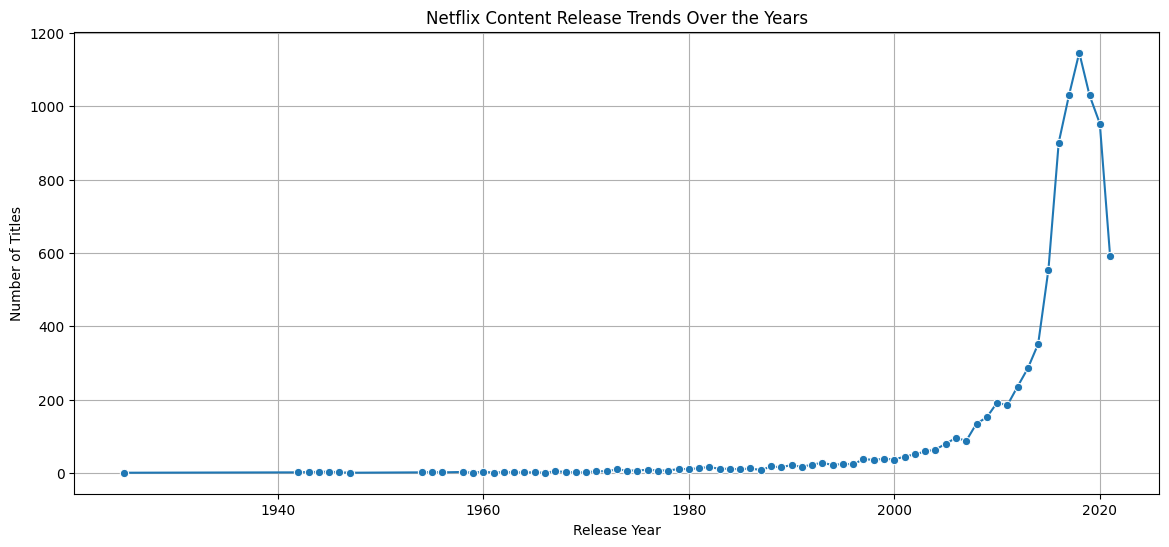

In [8]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=yearly_trends,
    x="release_year",
    y="total_titles",
    marker="o"
)

plt.title("Netflix Content Release Trends Over the Years")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True)
plt.show()

6. Compare Movies and TV Shows trends

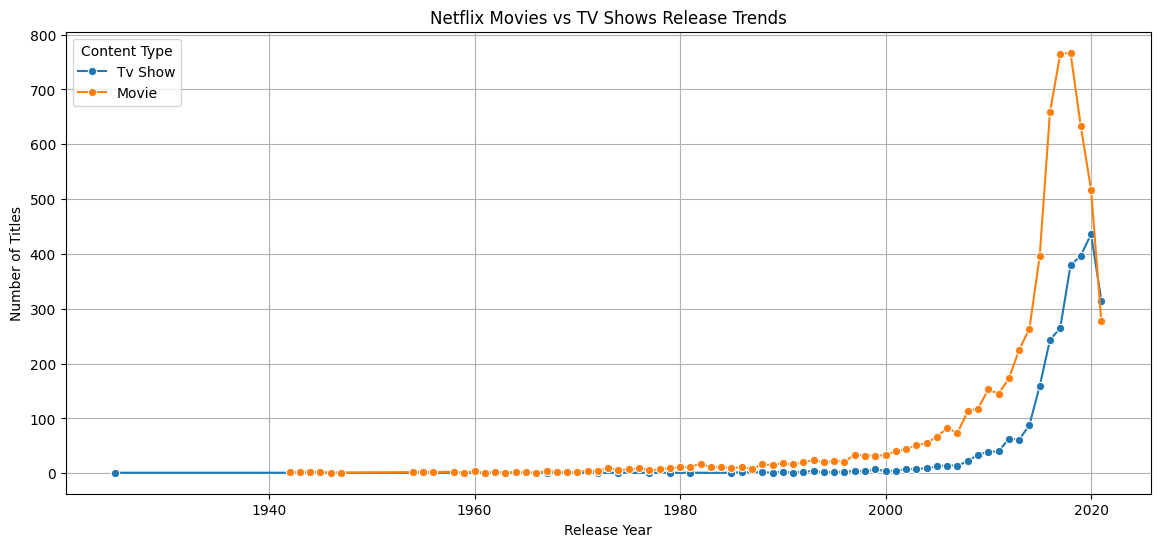

In [9]:
# Group content by year and type
content_by_type = (
    trend_df
    .groupby(["release_year", "type"])
    .size()
    .reset_index(name="total_titles")
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=content_by_type,
    x="release_year",
    y="total_titles",
    hue="type",
    marker="o"
)

plt.title("Netflix Movies vs TV Shows Release Trends")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend(title="Content Type")
plt.grid(True)
plt.show()

7. Prepare data for forecasting
We will use historical release-year data to train a Linear Regression model.

For this example, we will use the period from 2000 onwards to focus on more recent content trends.

In [10]:
# Filter recent content
forecast_df = yearly_trends[
    yearly_trends["release_year"] >= 2000
].copy()

# Prepare features and target
X = forecast_df[["release_year"]]
y = forecast_df["total_titles"]

# Display the data
forecast_df.head()

,release_year,total_titles
52,2000,37
53,2001,45
54,2002,51
55,2003,59
56,2004,64


8. Build the forecasting model
We will use Linear Regression to learn the relationship between release year and the number of Netflix titles.

In [11]:
# Create the model
model = LinearRegression()

# Train the model
model.fit(X, y)

# Predict historical values
y_pred = model.predict(X)

9. Evaluate the forecasting model
Evaluate the model using MAE, RMSE, and R².

In [12]:
# Calculate evaluation metrics
mae = mean_absolute_error(y, y_pred)

rmse = np.sqrt(mean_squared_error(y, y_pred))

r2 = r2_score(y, y_pred)

print("Model Evaluation")
print("-------------------------")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Model Evaluation
-------------------------
MAE: 164.95
RMSE: 191.99
R² Score: 0.7400


10. Forecast future Netflix content growth
Predict the number of titles for the next five years after the latest year in your dataset.

In [13]:
# Get the latest release year
last_year = forecast_df["release_year"].max()

# Create future years
future_years = pd.DataFrame({
    "release_year": range(last_year + 1, last_year + 6)
})

# Predict future content
future_predictions = model.predict(future_years)

# Store predictions
future_trends = pd.DataFrame({
    "release_year": future_years["release_year"],
    "predicted_titles": future_predictions.round().astype(int)
})

# Display predictions
future_trends

,release_year,predicted_titles
0,2022,963
1,2023,1014
2,2024,1065
3,2025,1116
4,2026,1167


11. Visualize future predictions
Combine historical trends with future predictions.

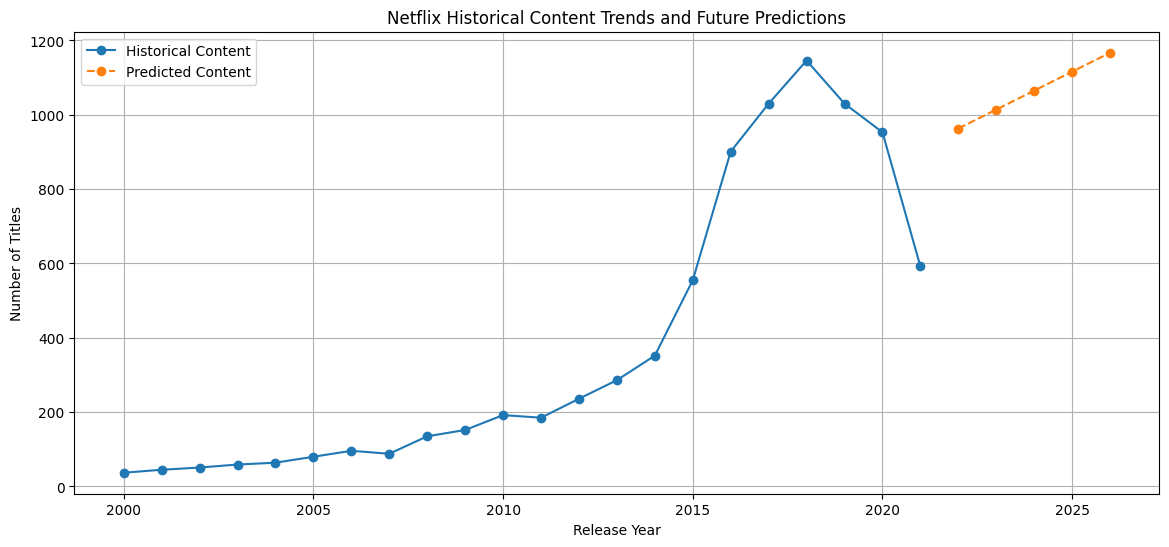

In [14]:
plt.figure(figsize=(14, 6))

# Historical data
plt.plot(
    forecast_df["release_year"],
    forecast_df["total_titles"],
    marker="o",
    label="Historical Content"
)

# Future predictions
plt.plot(
    future_trends["release_year"],
    future_trends["predicted_titles"],
    marker="o",
    linestyle="--",
    label="Predicted Content"
)

plt.title("Netflix Historical Content Trends and Future Predictions")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.grid(True)
plt.show()

1. Historical content trends: Netflix content releases increased over the years, indicating growth in the platform's content library.
2. Content comparison: Movies and TV shows show different release patterns, with movies representing a larger proportion of the dataset.
3. Forecasting: The Linear Regression model estimates future content trends based on historical release-year patterns.
4. Model performance: MAE, RMSE, and R² help assess how well the model captures historical trends.
5. Business insights: Understanding content growth can help identify changes in content production and support strategic planning.
Important: These predictions are estimates based on release years in the Netflix dataset. They do not represent confirmed future Netflix production plans. Also, release_year measures when a title was released, not necessarily when Netflix acquired or produced it.